In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import zipfile

DRIVE_DIR = Path('/content/drive/MyDrive/ML_PROM02')
ZIP_PATH = DRIVE_DIR / 'DocForge_Colab.zip'
PROJECT_ROOT = Path('/content/DocForge')
CHECKPOINT_DIR = DRIVE_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.is_file(), f'Missing project ZIP: {ZIP_PATH}'
required = ['src/docforge/models/unet.py', 'src/docforge/training/dataset.py', 'src/docforge/training/metrics.py']
if not all((PROJECT_ROOT / f).is_file() and (PROJECT_ROOT / f).stat().st_size > 0 for f in required):
    PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(PROJECT_ROOT)
    print('Restored working source from ZIP')
else:
    print('Working source already exists; no extraction needed')
for rel in required:
    f = PROJECT_ROOT / rel
    print(rel, 'OK' if f.is_file() and f.stat().st_size else 'MISSING/EMPTY')
assert all((PROJECT_ROOT / f).is_file() and (PROJECT_ROOT / f).stat().st_size for f in required), 'ZIP layout differs; inspect extraction before continuing'

Mounted at /content/drive
Restored working source from ZIP
src/docforge/models/unet.py OK
src/docforge/training/dataset.py OK
src/docforge/training/metrics.py OK


In [2]:
%pip -q install lmdb pandas matplotlib kaggle

In [3]:
import sys, os, importlib
import numpy as np
import pandas as pd
import torch, lmdb
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

SRC = str(PROJECT_ROOT / 'src')
if SRC not in sys.path:
    sys.path.insert(0, SRC)
# Avoid accidentally importing the incomplete GitHub-clone modules.
for name in list(sys.modules):
    if name == 'docforge' or name.startswith('docforge.'):
        del sys.modules[name]
importlib.invalidate_caches()
from docforge.models.unet import UNet
from docforge.training.dataset import DocTamperDataset
from docforge.training.metrics import combined_loss, calculate_metrics

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Working source:', SRC)
print('PyTorch:', torch.__version__, '| Device:', device)
print('All three project modules imported successfully')

Working source: /content/DocForge/src
PyTorch: 2.14.1+cpu | Device: cpu
All three project modules imported successfully


In [20]:
# Locate Training Dataset
LMDB_SOURCE = Path('/content/doctamper/DocTamperV1-TrainingSet')
LMDB_TARGET = PROJECT_ROOT / 'data/raw/large'
CSV_PATH = PROJECT_ROOT / 'data/splits/large_dataset_split.csv'

def has_lmdb(folder):
    return folder.is_dir() and (folder / 'data.mdb').is_file()

print('Downloaded LMDB:', has_lmdb(LMDB_SOURCE))
print('Linked LMDB:', has_lmdb(LMDB_TARGET))
print('Split CSV:', CSV_PATH.is_file())
print('Checkpoint:', (CHECKPOINT_DIR / 'unet_pilot.pth').is_file())

Downloaded LMDB: True
Linked LMDB: True
Split CSV: True
Checkpoint: True


In [5]:
# OPTIONAL — authenticate only if the dataset is missing.
from getpass import getpass
if not has_lmdb(LMDB_SOURCE) and not has_lmdb(LMDB_TARGET):
    os.environ['KAGGLE_API_TOKEN'] = getpass('Enter Kaggle API token (hidden): ')
else:
    print('LMDB already available — skip Kaggle authentication')

Enter Kaggle API token (hidden): ··········


In [12]:
# OPTIONAL — large download; will not run if the LMDB already exists.
import subprocess, shutil
if not has_lmdb(LMDB_SOURCE) and not has_lmdb(LMDB_TARGET):
    print('Free disk space:', shutil.disk_usage('/content').free // (1024**3), 'GiB')
    LMDB_SOURCE.mkdir(parents=True, exist_ok=True)
    subprocess.run(['kaggle', 'datasets', 'download', '-d', 'dinmkeljiame/doctamper',
                    '-f', 'DocTamperV1-TrainingSet/data.mdb', '-p', '/content/doctamper'], check=True)
    archive = LMDB_SOURCE / 'data.mdb.zip'
    assert archive.exists(), f'Expected archive not found: {archive}'
    subprocess.run(['unzip', '-o', str(archive), '-d', str(LMDB_SOURCE)], check=True)
else:
    print('LMDB already present; download skipped')
assert has_lmdb(LMDB_SOURCE) or has_lmdb(LMDB_TARGET), 'LMDB not found after download'

LMDB already present; download skipped


In [10]:
from pathlib import Path

root = Path("/content/doctamper")

print("Dataset folder exists:", root.exists())

if root.exists():
    for path in root.rglob("*"):
        if path.is_file():
            print(
                path.relative_to(root),
                "|",
                round(path.stat().st_size / 1024**2, 2),
                "MiB"
            )

Dataset folder exists: True
data.mdb.zip | 14739.48 MiB


In [11]:
# Extract the dataset file
from pathlib import Path
import subprocess
import zipfile

archive = Path("/content/doctamper/data.mdb.zip")
destination = Path("/content/doctamper/DocTamperV1-TrainingSet")

destination.mkdir(parents=True, exist_ok=True)

print("Archive exists:", archive.exists())

with zipfile.ZipFile(archive) as z:
    print("Archive contents:", z.namelist()[:10])

    if not (destination / "data.mdb").exists():
        z.extractall(destination)
        print("Extraction completed!")
    else:
        print("Dataset already extracted.")

Archive exists: True
Archive contents: ['data.mdb']
Extraction completed!


In [13]:
# check the extracted dataset
from pathlib import Path

root = Path("/content/doctamper/DocTamperV1-TrainingSet")

for file in root.rglob("data.mdb"):
    print("LMDB found:", file)
    print("Size:", round(file.stat().st_size / 1024**3, 2), "GiB")

LMDB found: /content/doctamper/DocTamperV1-TrainingSet/data.mdb
Size: 15.33 GiB


In [14]:
### Connect the LMDB and create or reuse the split dataset (CSV file split) for the training
import numpy as np
PROJECT_ROOT.joinpath('data/raw').mkdir(parents=True, exist_ok=True)
CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
if not has_lmdb(LMDB_TARGET):
    assert has_lmdb(LMDB_SOURCE), 'Run Section 4 or provide existing LMDB first'
    if LMDB_TARGET.is_symlink() and not LMDB_TARGET.exists():
        LMDB_TARGET.unlink()
    if not LMDB_TARGET.exists():
        LMDB_TARGET.symlink_to(LMDB_SOURCE, target_is_directory=True)
assert has_lmdb(LMDB_TARGET), f'LMDB unavailable at {LMDB_TARGET}'

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    print('Reused existing split:', CSV_PATH)
else:
    env = lmdb.open(str(LMDB_TARGET), readonly=True, lock=False, readahead=False, meminit=False)
    try:
        with env.begin() as txn:
            raw = txn.get(b'num-samples')
            assert raw is not None, 'LMDB num-samples key missing'
            num_samples = int(raw)
    finally:
        env.close()
    df = pd.DataFrame({'sample_id': range(1, num_samples + 1)})
    df['image_key'] = df['sample_id'].map(lambda i: f'image-{i:09d}')
    df['label_key'] = df['sample_id'].map(lambda i: f'label-{i:09d}')
    rng = np.random.default_rng(42)
    indices = rng.permutation(num_samples)
    df['split'] = 'validation'
    df.loc[indices[:int(num_samples * .9)], 'split'] = 'train'
    df.to_csv(CSV_PATH, index=False)
    print('Created split:', CSV_PATH)
print(df['split'].value_counts())
print('Columns:', df.columns.tolist())

Created split: /content/DocForge/data/splits/large_dataset_split.csv
split
train         108000
validation     12000
Name: count, dtype: int64
Columns: ['sample_id', 'image_key', 'label_key', 'split']


In [15]:
### Smoke test
sample_df = df[df['split'] == 'train'].head(1)
assert len(sample_df), 'No training rows in split'
probe = DocTamperDataset(sample_df, str(LMDB_TARGET))
image, mask = probe[0]
print('Image:', tuple(image.shape), 'Mask:', tuple(mask.shape))
# Release probe LMDB connection if opened lazily.
if getattr(probe, 'env', None) is not None:
    probe.env.close()
    probe.env = None

del probe
model = UNet(in_channels=3, out_channels=1).to(device)
print('Model initialised:', type(model).__name__)
# Avoid a 512x512 forward pass until the dataset and model are confirmed working.

Image: (3, 512, 512) Mask: (1, 512, 512)
Model initialised: UNet


In [16]:
### Evaluate ur save pilot checkpoints
checkpoint_path = CHECKPOINT_DIR / 'unet_pilot.pth'
assert checkpoint_path.is_file(), f'Checkpoint not found: {checkpoint_path}'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'], strict=True)
model = model.to(device).eval()
print('Checkpoint loaded successfully')
print('Saved validation loss:', checkpoint.get('val_loss'))
print('Saved validation metrics:', checkpoint.get('val_metrics'))

Checkpoint loaded successfully
Saved validation loss: 1.2282967710494994
Saved validation metrics: {'dice': 0.06356140273239476, 'iou': 0.037143092674906494, 'precision': 0.09945720436386273, 'recall': 0.09572286994626131}


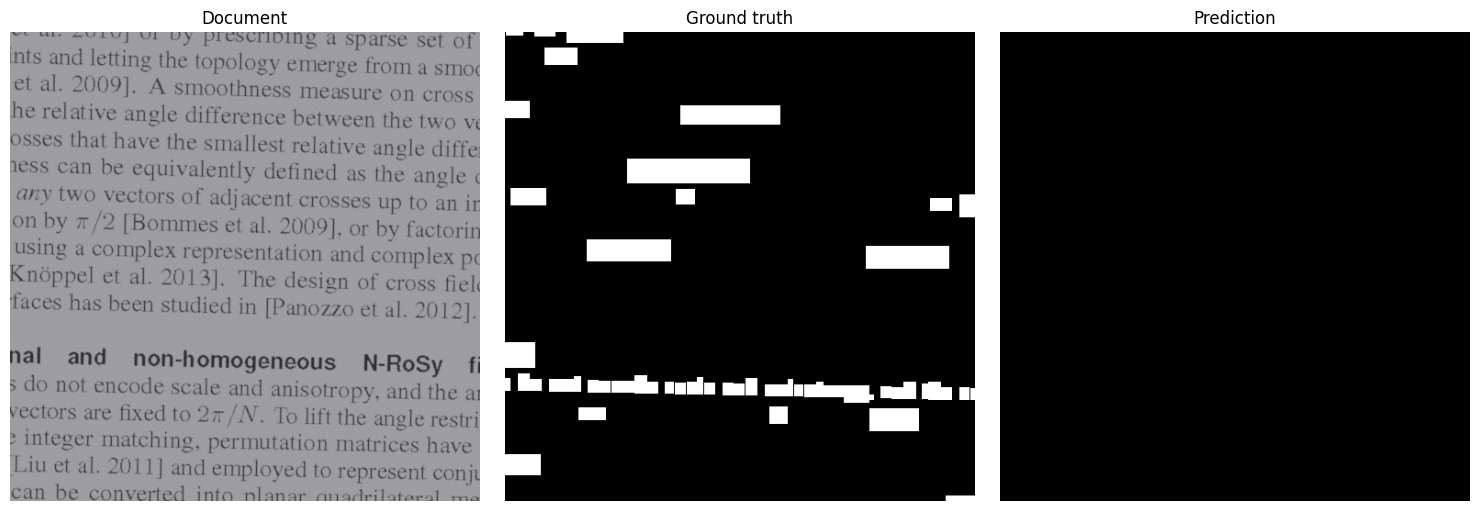

In [17]:
# OPTIONAL: visualise one validation example (uses the loaded checkpoint).
val_df = df[df['split'] == 'validation'].head(1)
assert len(val_df), 'No validation samples'
val_probe = DocTamperDataset(val_df, str(LMDB_TARGET))
image, mask = val_probe[0]
with torch.inference_mode():
    probability = torch.sigmoid(model(image.unsqueeze(0).to(device)))[0, 0].cpu()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(image.permute(1, 2, 0).cpu().numpy()); axes[0].set_title('Document')
axes[1].imshow(mask.squeeze().cpu().numpy(), cmap='gray'); axes[1].set_title('Ground truth')
axes[2].imshow((probability >= .5).numpy(), cmap='gray'); axes[2].set_title('Prediction')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
if getattr(val_probe, 'env', None) is not None:
    val_probe.env.close(); val_probe.env = None
del val_probe

In [18]:
# INSPECTION ONLY — no training starts here.
import inspect
train_file = PROJECT_ROOT / 'src/docforge/training/train.py'
print('Training module size:', train_file.stat().st_size if train_file.exists() else 'MISSING')
if train_file.exists():
    print(train_file.read_text()[:12000])
print('To resume training, load BOTH model and optimiser states with matching setup,')
print('and save to a NEW checkpoint name so unet_pilot.pth is preserved.')

Training module size: 4702

from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import DataLoader

from docforge.models.unet import UNet
from docforge.training.dataset import DocTamperDataset
from docforge.training.metrics import combined_loss, calculate_metrics


def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0.0

    for batch_idx, (images, masks) in enumerate(loader):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        if batch_idx % 25 == 0:
            print(
                f"Batch [{batch_idx + 1}/{

In [19]:
# OPTIONAL: inspect clone status only; does not modify GitHub.
import subprocess
GIT_REPO = Path('/content/PROM02_240291316')
if GIT_REPO.is_dir() and (GIT_REPO / '.git').exists():
    subprocess.run(['git', 'status', '--short'], cwd=GIT_REPO)
    print('Working source:', PROJECT_ROOT)
    print('Git clone:', GIT_REPO)
else:
    print('Git clone not present; skip GitHub section for now')

Git clone not present; skip GitHub section for now


In [2]:
from pathlib import Path
import subprocess

GIT_REPO = Path("/content/PROM02_240291316")
PROJECT_ROOT = Path("/content/DocForge")

if not (GIT_REPO / ".git").exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/odette-eleanor/PROM02_240291316.git",
            str(GIT_REPO)
        ],
        check=True
    )
else:
    print("GitHub repository already connected.")

print("\nGitHub repository:", GIT_REPO)
print("Working project exists:", PROJECT_ROOT.exists())

subprocess.run(["git", "status", "-sb"], cwd=GIT_REPO, check=True)


GitHub repository: /content/PROM02_240291316
Working project exists: False


CompletedProcess(args=['git', 'status', '-sb'], returncode=0)

In [4]:
from pathlib import Path

for notebook in Path("/content/drive/MyDrive").rglob(
    "DocForge_UNet_Training_v2.ipynb"
):
    print("Found:", notebook)

In [6]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/Colab Notebooks")

for file in folder.glob("*.ipynb"):
    print(file.name)

In [7]:
from pathlib import Path

PROJECT_ROOT = Path("/content/DocForge")

print("Working project:", PROJECT_ROOT.exists())

for name in [
    "src/docforge/models/unet.py",
    "src/docforge/training/dataset.py",
    "src/docforge/training/metrics.py",
    "src/docforge/training/train.py",
]:
    file = PROJECT_ROOT / name
    print(name, "OK" if file.exists() and file.stat().st_size > 0 else "MISSING")

Working project: False
src/docforge/models/unet.py MISSING
src/docforge/training/dataset.py MISSING
src/docforge/training/metrics.py MISSING
src/docforge/training/train.py MISSING


In [8]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

for file in Path("/content/drive/MyDrive").rglob("DocForge_Colab.zip"):
    print("Backup found:", file)

Mounted at /content/drive
Backup found: /content/drive/MyDrive/ML_PROM02/DocForge_Colab.zip


In [9]:
for file in Path("/content/drive/MyDrive").rglob("*.zip"):
    print(file)

/content/drive/MyDrive/ML_PROM02/DocForge_Colab.zip


In [1]:
### Before training, changed the runtime to T4
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
### for pushing google collab .ipynb to the git??
from pathlib import Path

notebooks = list(
    Path("/content/drive/MyDrive").rglob("*.ipynb")
)

for notebook in notebooks:
    print(notebook)
